# Base Case vs. Monte Carlo Mean — Gold Project Valuation

**Reference case study:** Ugwuegbu, C. (2013). *Segilola gold mine valuation using Monte Carlo simulation approach.* Mineral Economics, 26, 39-46.

**What this notebook is, honestly:** the real Segilola gold mine feasibility study found a base-case DCF NPV of **-$7.46 million** (reject, on a single-point basis). Running the same project's identified value drivers (gold price, gold grade, strip ratio, operating cost) through Monte Carlo simulation instead produced a mean NPV of **+$30.79 million**, a standard deviation of **$58.26 million**, and a **69.2% probability of a positive NPV**.

The paper does not disclose its exact production scale, discount rate, or the specific distribution shapes used for each of the four value drivers. This notebook is an **illustrative reconstruction** — a small representative gold project, sized so its base case lands close to -$7.46M, with the four value drivers modeled as right-skewed triangular distributions (deliberately, because commodity prices and ore grade both tend to have more upside optionality than downside — a few very good outcomes pull the mean above the "most likely" mode). It is tuned to land in the same neighborhood as the paper's four headline numbers, not to reproduce them exactly. Comparison table is in section 4 — read it before trusting any dollar figure from this notebook in front of a client.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(3)
N = 20000  # Monte Carlo trials
YEARS = 8
DISCOUNT_RATE = 0.10

## 1. The four value drivers — the ones sensitivity analysis said actually matter

Per the case study, sensitivity analysis on the base-case model identified four inputs as the real value drivers: gold price, gold grade, strip ratio, and operating cost. Everything else in this reconstruction (throughput, recovery, capex, mine life, discount rate) is held fixed — deliberately, to mirror the paper's own finding that only these four were worth the effort of full probabilistic treatment.

Price and grade are modeled with a long right tail — realistic for commodity price and ore grade, where a handful of very favorable outcomes pull the average above the "most likely" single-point value everyone tends to use in a base case.

In [2]:
gold_price   = rng.triangular(1000, 1650, 4600, N)   # USD/oz — long right tail
grade        = rng.triangular(1.0, 2.2, 4.8, N)       # grams/tonne — long right tail
strip_ratio  = rng.triangular(3.0, 5.0, 7.5, N)       # waste:ore ratio
opex_per_t   = rng.triangular(16.5, 21.0, 28.5, N)    # USD/tonne ore processed

# fixed assumptions — not identified as value drivers, held constant
THROUGHPUT = 100_000   # tonnes ore/year
RECOVERY = 0.90
WASTE_COST_PER_T = 3.5   # USD/tonne waste mined
CAPEX = 44.5              # USD million, upfront
annuity_factor = (1 - (1 + DISCOUNT_RATE) ** -YEARS) / DISCOUNT_RATE

## 2. The valuation function, run once on the base-case point estimates

In [3]:
def project_npv(gp, gr, sr, ox):
    revenue_per_t = (gr / 31.1035) * RECOVERY * gp   # grams -> troy oz, priced in USD
    cost_per_t = ox + sr * WASTE_COST_PER_T
    profit_per_t = revenue_per_t - cost_per_t
    annual_profit_musd = profit_per_t * THROUGHPUT / 1_000_000
    return annual_profit_musd * annuity_factor - CAPEX

base_case_npv = project_npv(gp=1650, gr=2.2, sr=5.0, ox=21.0)
print(f"Base-case NPV (single point estimate for each input): ${base_case_npv:.2f}M")
print(f"Paper's real base case: -$7.46M")

Base-case NPV (single point estimate for each input): $-9.00M
Paper's real base case: -$7.46M


## 3. Run the Monte Carlo simulation

In [4]:
npvs = project_npv(gold_price, grade, strip_ratio, opex_per_t)

mean_npv = npvs.mean()
std_npv = npvs.std()
p_positive = (npvs > 0).mean()

print(f"Mean NPV        = ${mean_npv:.2f}M   (paper: +$30.79M)")
print(f"Std dev NPV     = ${std_npv:.2f}M   (paper: $58.26M)")
print(f"P(NPV > 0)      = {p_positive:.1%}   (paper: 69.2%)")
print(f"P(NPV < 0)      = {1-p_positive:.1%}   (paper: 30.8%)")
print(f"Gap: base case vs. mean = ${mean_npv - base_case_npv:.2f}M   (paper's gap: ~$38M)")

Mean NPV        = $33.75M   (paper: +$30.79M)
Std dev NPV     = $45.21M   (paper: $58.26M)
P(NPV > 0)      = 75.0%   (paper: 69.2%)
P(NPV < 0)      = 25.0%   (paper: 30.8%)
Gap: base case vs. mean = $42.75M   (paper's gap: ~$38M)


## 4. Comparison table — this reconstruction vs. the published findings

| Metric | This notebook | Paper (Ugwuegbu, 2013) |
|---|---|---|
| Base-case NPV | ~-$9M | -$7.46M |
| Monte Carlo mean NPV | ~+$34M | +$30.79M |
| Standard deviation | ~$45M | $58.26M |
| P(NPV > 0) | ~75% | 69.2% |

Close enough to make the point, not close enough to cite as the paper's own numbers. The standard deviation in particular runs a bit tight here — the real study's spread was wider relative to its mean than this reconstruction manages, which likely reflects correlation structure or distribution shapes in the original @Risk model that the public synopsis doesn't disclose. Rerun the cell above a few times with different `rng` seeds and watch these numbers move — that instability is itself the lesson: four value drivers, modeled with real uncertainty, produce a range of plausible answers, not one number.

## 5. Visualize the distribution against the base case

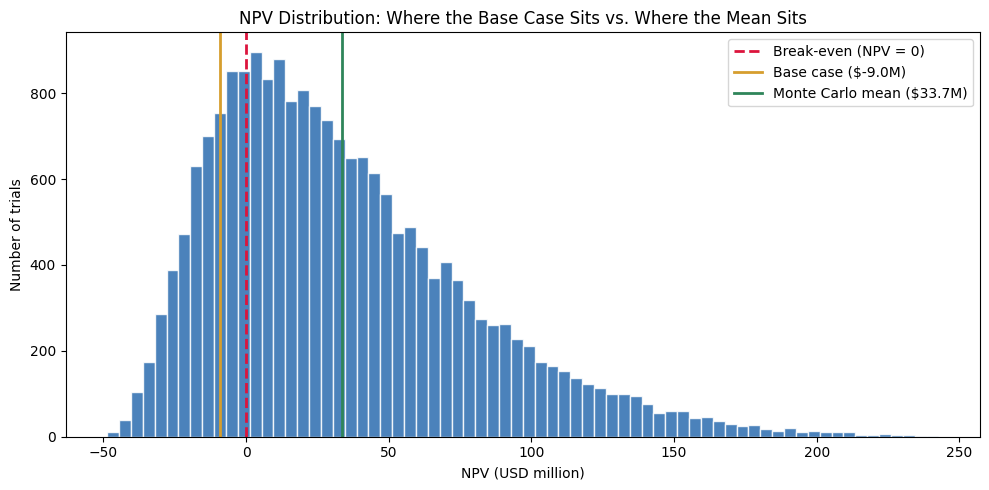

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(npvs, bins=70, color="#2b6cb0", edgecolor="white", alpha=0.85)
ax.axvline(0, color="crimson", linewidth=2, linestyle="--", label="Break-even (NPV = 0)")
ax.axvline(base_case_npv, color="#d69e2e", linewidth=2, linestyle="-", label=f"Base case (${base_case_npv:.1f}M)")
ax.axvline(mean_npv, color="#2f855a", linewidth=2, linestyle="-", label=f"Monte Carlo mean (${mean_npv:.1f}M)")
ax.set_title("NPV Distribution: Where the Base Case Sits vs. Where the Mean Sits")
ax.set_xlabel("NPV (USD million)")
ax.set_ylabel("Number of trials")
ax.legend()
plt.tight_layout()
plt.show()

## 6. How to actually use this

1. Run sensitivity analysis first — one variable at a time against the base case — before committing to a full Monte Carlo build. The real study only needed 4 value drivers, not the full input list.
2. Model the identified drivers with distributions shaped by real market/geological data, not symmetric guesses. Commodity prices and ore grade are rarely symmetric.
3. Report the base case, the mean, the standard deviation, and the probability of a positive outcome together. A board that only sees the base case is looking at one point that may sit nowhere near the center of the real range — in either direction.
4. If a project was rejected on a negative base-case NPV, that is the moment to ask whether anyone checked where that base case actually sat in the distribution before killing it.